# Exploratory Data Analysis: CAISO Cluster 15 Interconnection Requests

## Purpose
This notebook loads and analyzes both workbook sheets:

- `Cluster 15 `: 86 currently active/unresolved projects
- `Withdrawn`: 84 withdrawn projects

The active records are right-censored and do not provide successful outcomes. This workbook is therefore useful for current-cohort analysis, withdrawal analysis, and inference—but it cannot independently train an operational-versus-withdrawn classifier.

## 1. Imports and paths

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("../Data_ML_SQL/CASIO_Cluster_15_Interconnection_Requests.xlsx")
C14_PATH = Path("../Data_ML_SQL/CASIO_Cluster_14_and_Prior_Interconnection_Requests.xlsx")
BERKELEY_PATH = Path("../Data_ML_SQL/Berkeley_LabQueue_Data_2025.xlsx")
assert DATA_PATH.exists(), f"Missing data file: {DATA_PATH}"
print("Imports and paths ready.")

Imports and paths ready.


## 2. Load and harmonize every sheet

In [2]:
excel_file = pd.ExcelFile(DATA_PATH)
print("Workbook sheets:", excel_file.sheet_names)

def snake_case(value):
    value = str(value).replace("\n", " ").strip().lower()
    value = re.sub(r"[^a-z0-9]+", "_", value)
    return value.strip("_")

def load_c15_sheet(sheet_name, status):
    frame = pd.read_excel(DATA_PATH, sheet_name=sheet_name)
    frame.columns = [snake_case(col) for col in frame.columns]
    frame = frame.rename(columns={
        "queue_number": "queue_id",
        "project_number": "project_id",
        "generation_fuel_1": "fuel_1",
        "generation_fuel_2": "fuel_2",
        "generation_fuel_3": "fuel_3",
        "net_mw_1": "mw_1",
        "net_mw_2": "mw_2",
        "net_mw_3": "mw_3",
        "net_mw_poi": "net_mw_poi",
        "project_county": "county",
        "project_state": "state",
        "voltage_kv": "voltage_kv",
        "requested_cod": "requested_cod",
        "queue_date": "queue_date",
        "application_date": "application_date",
        "withdrawal_date": "withdrawal_date",
    })
    frame["source_sheet"] = sheet_name
    frame["record_status"] = status
    return frame

active = load_c15_sheet("Cluster 15 ", "active")
withdrawn = load_c15_sheet("Withdrawn", "withdrawn")
all_projects = pd.concat([active, withdrawn], ignore_index=True, sort=False)

manifest = pd.DataFrame({
    "sheet": ["Cluster 15 ", "Withdrawn"],
    "projects": [len(active), len(withdrawn)],
    "columns": [active.shape[1], withdrawn.shape[1]],
    "record_status": ["active", "withdrawn"],
})
display(manifest)
print(f"Combined Cluster 15 projects: {len(all_projects)}")

Workbook sheets: ['Cluster 15 ', 'Withdrawn']


,sheet,projects,columns,record_status
0,Cluster 15,86,22,active
1,Withdrawn,84,23,withdrawn


Combined Cluster 15 projects: 170


## 3. Types, dates, and engineered fields

In [3]:
date_cols = ["requested_cod", "queue_date", "application_date", "withdrawal_date"]
numeric_cols = ["mw_1", "mw_2", "mw_3", "net_mw_poi", "voltage_kv"]

for col in date_cols:
    if col not in all_projects:
        all_projects[col] = pd.NaT
    all_projects[col] = pd.to_datetime(all_projects[col], errors="coerce")

for col in numeric_cols:
    all_projects[col] = pd.to_numeric(all_projects[col], errors="coerce")

all_projects["component_mw_sum"] = all_projects[["mw_1", "mw_2", "mw_3"]].fillna(0).sum(axis=1)
all_projects["poi_component_delta"] = (
    all_projects["net_mw_poi"] - all_projects["component_mw_sum"]
)
all_projects["is_hybrid"] = all_projects[["fuel_2", "fuel_3"]].notna().any(axis=1)
all_projects["days_application_to_queue"] = (
    all_projects["queue_date"] - all_projects["application_date"]
).dt.days
all_projects["days_queue_to_cod"] = (
    all_projects["requested_cod"] - all_projects["queue_date"]
).dt.days
all_projects["days_queue_to_withdrawal"] = (
    all_projects["withdrawal_date"] - all_projects["queue_date"]
).dt.days
all_projects["cod_year"] = all_projects["requested_cod"].dt.year

print("Queue date values:")
display(all_projects["queue_date"].value_counts(dropna=False))
print("Date consistency exceptions:")
print("Application after queue:",
      (all_projects["days_application_to_queue"] < 0).sum())
print("Requested COD before queue:",
      (all_projects["days_queue_to_cod"] < 0).sum())

Queue date values:


queue_date
2025-02-12    170
Name: count, dtype: int64

Date consistency exceptions:
Application after queue: 2
Requested COD before queue: 0


## 4. Data quality and integrity

In [4]:
def quality_table(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_pct": (frame.isna().mean() * 100).round(2),
        "unique": frame.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False)

quality_active = quality_table(active)
quality_withdrawn = quality_table(withdrawn)
quality_union = quality_table(all_projects)

quality_summary = pd.DataFrame({
    "cohort": ["active", "withdrawn", "union"],
    "rows": [len(active), len(withdrawn), len(all_projects)],
    "exact_duplicates": [
        active.duplicated().sum(),
        withdrawn.duplicated().sum(),
        all_projects.duplicated().sum(),
    ],
    "duplicate_queue_ids": [
        active["queue_id"].duplicated().sum(),
        withdrawn["queue_id"].duplicated().sum(),
        all_projects["queue_id"].duplicated().sum(),
    ],
    "missing_cells_pct": [
        active.isna().mean().mean() * 100,
        withdrawn.isna().mean().mean() * 100,
        all_projects.isna().mean().mean() * 100,
    ],
})
display(quality_summary.round(2))
display(quality_union)

,cohort,rows,exact_duplicates,duplicate_queue_ids,missing_cells_pct
0,active,86,0,0,13.95
1,withdrawn,84,0,0,15.01
2,union,170,0,0,14.24


,dtype,missing,missing_pct,unique
mw_3,float64,169,99.41,1
fuel_3,object,169,99.41,1
fuel_2,str,108,63.53,4
mw_2,float64,108,63.53,61
days_queue_to_withdrawal,float64,86,50.59,35
withdrawal_date,datetime64[us],86,50.59,35
component_mw_sum,float64,0,0.00,163
service_type,str,0,0.00,3
source_sheet,str,0,0.00,2
record_status,str,0,0.00,2


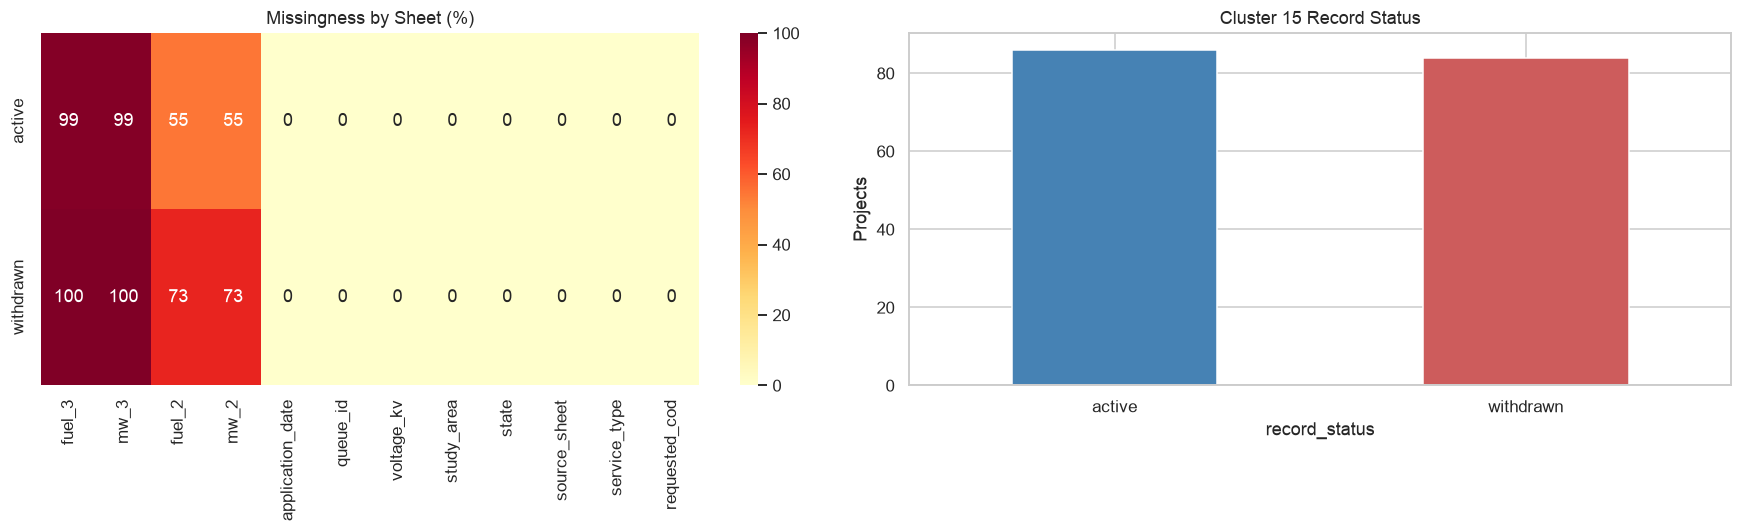

In [5]:
missing_matrix = pd.DataFrame({
    "active": active.isna().mean() * 100,
    "withdrawn": withdrawn.isna().mean() * 100,
}).T
plot_cols = missing_matrix.max().sort_values(ascending=False).head(12).index

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(missing_matrix[plot_cols], annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[0])
axes[0].set_title("Missingness by Sheet (%)")

status_counts = all_projects["record_status"].value_counts()
status_counts.plot.bar(ax=axes[1], color=["steelblue", "indianred"])
axes[1].set_title("Cluster 15 Record Status")
axes[1].set_ylabel("Projects")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 5. Outcome interpretation

`withdrawn` is a known terminal event. `active` means the project was still unresolved at the report date; it is not a success label. Because there are no operational/completed projects in this workbook, `active` versus `withdrawn` is not a valid standalone terminal-outcome training target.

In [6]:
status_summary = (
    all_projects.groupby("record_status")
                .agg(
                    projects=("queue_id", "size"),
                    total_poi_mw=("net_mw_poi", "sum"),
                    median_poi_mw=("net_mw_poi", "median"),
                    hybrid_share=("is_hybrid", "mean"),
                )
)
display(status_summary)

,projects,total_poi_mw,median_poi_mw,hybrid_share
record_status,,,,
active,86,28449.18,300.0,0.453488
withdrawn,84,30563.53,325.0,0.273810


## 6. Capacity distributions and hybrid configurations

,feature,n,mean,median,std,min,max,skew,kurtosis
0,net_mw_poi,170,347.13,300.00,252.45,0.00,1150.00,1.33,1.75
1,component_mw_sum,170,498.08,365.54,467.38,10.07,2346.96,2.03,4.24
2,days_queue_to_cod,170,1784.49,1753.00,489.12,114.00,2879.00,-0.07,-0.48


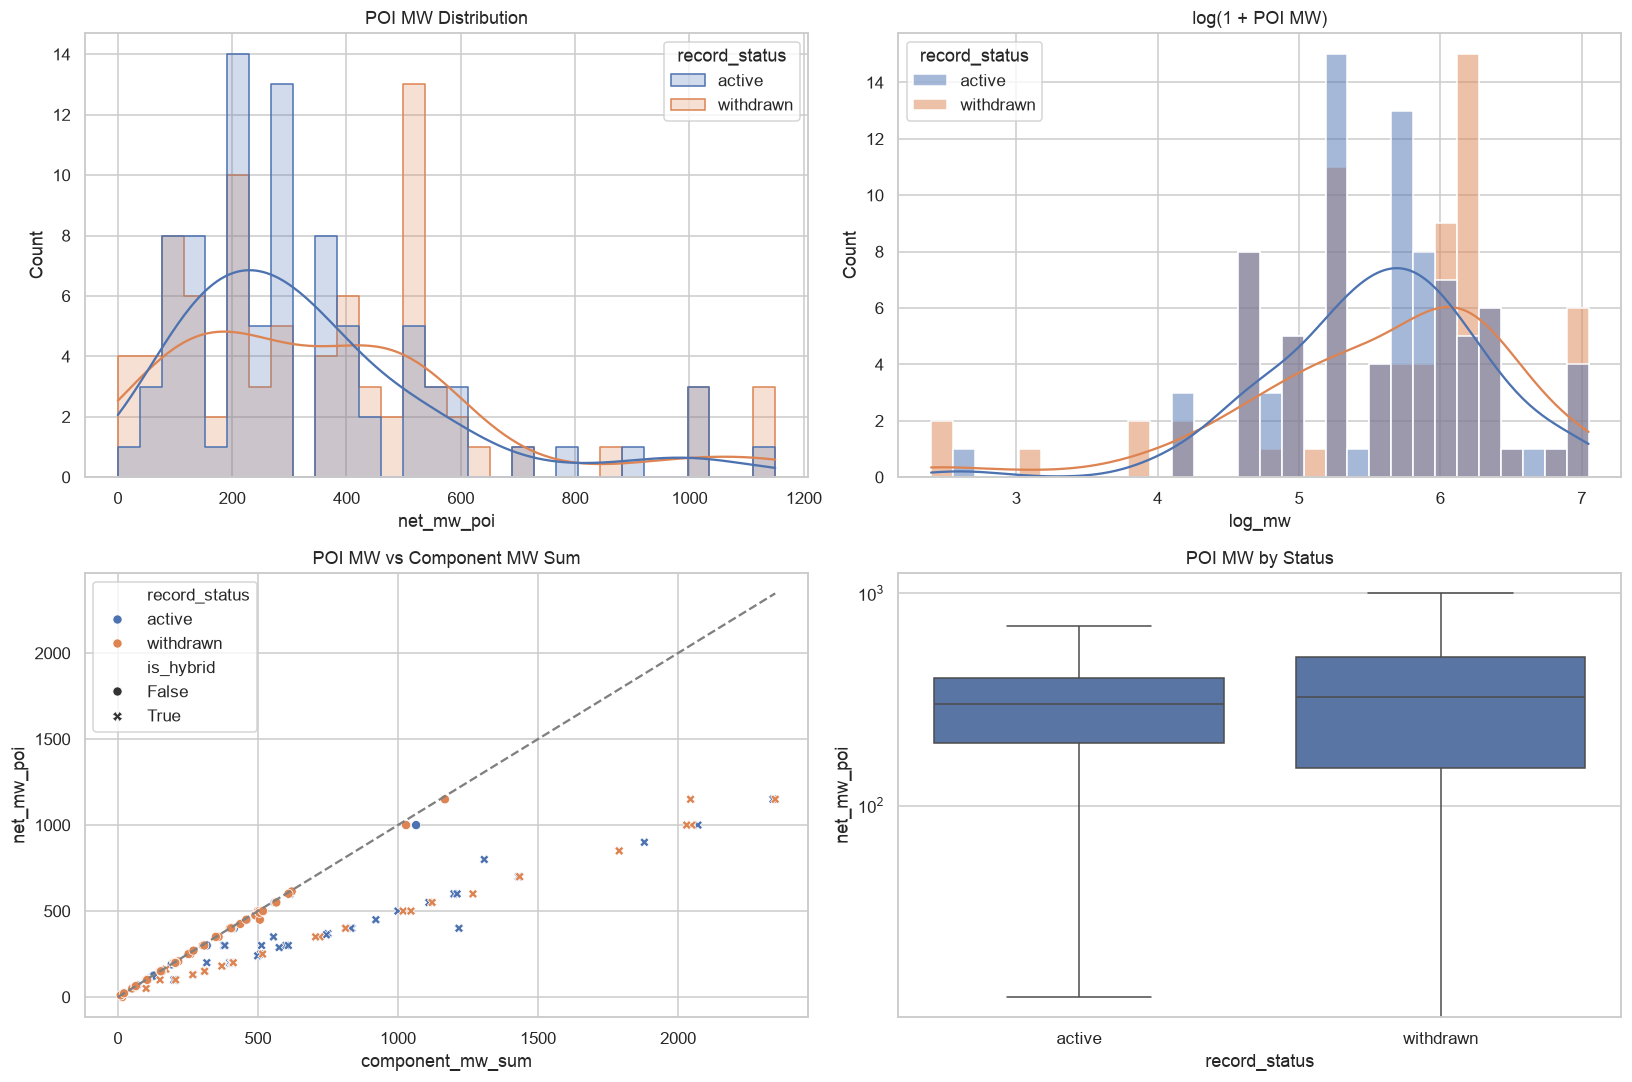

In [7]:
def summarize_numeric(data, col):
    x = pd.to_numeric(data[col], errors="coerce").dropna()
    return {
        "feature": col,
        "n": len(x),
        "mean": x.mean(),
        "median": x.median(),
        "std": x.std(),
        "min": x.min(),
        "max": x.max(),
        "skew": stats.skew(x, nan_policy="omit") if len(x) > 2 else np.nan,
        "kurtosis": stats.kurtosis(x, nan_policy="omit") if len(x) > 3 else np.nan,
    }

display(pd.DataFrame([
    summarize_numeric(all_projects, "net_mw_poi"),
    summarize_numeric(all_projects, "component_mw_sum"),
    summarize_numeric(all_projects, "days_queue_to_cod"),
]).round(2))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(data=all_projects, x="net_mw_poi", hue="record_status",
             bins=30, kde=True, element="step", ax=axes[0, 0])
axes[0, 0].set_title("POI MW Distribution")

positive = all_projects[all_projects["net_mw_poi"] > 0].copy()
sns.histplot(data=positive.assign(log_mw=np.log1p(positive["net_mw_poi"])),
             x="log_mw", hue="record_status", bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("log(1 + POI MW)")

sns.scatterplot(data=all_projects, x="component_mw_sum", y="net_mw_poi",
                hue="record_status", style="is_hybrid", ax=axes[1, 0])
limit = max(all_projects["component_mw_sum"].max(), all_projects["net_mw_poi"].max())
axes[1, 0].plot([0, limit], [0, limit], "--", color="gray")
axes[1, 0].set_title("POI MW vs Component MW Sum")

sns.boxplot(data=all_projects, x="record_status", y="net_mw_poi",
            showfliers=False, ax=axes[1, 1])
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("POI MW by Status")
plt.tight_layout()
plt.show()

## 7. Technology, service, voltage, and geography

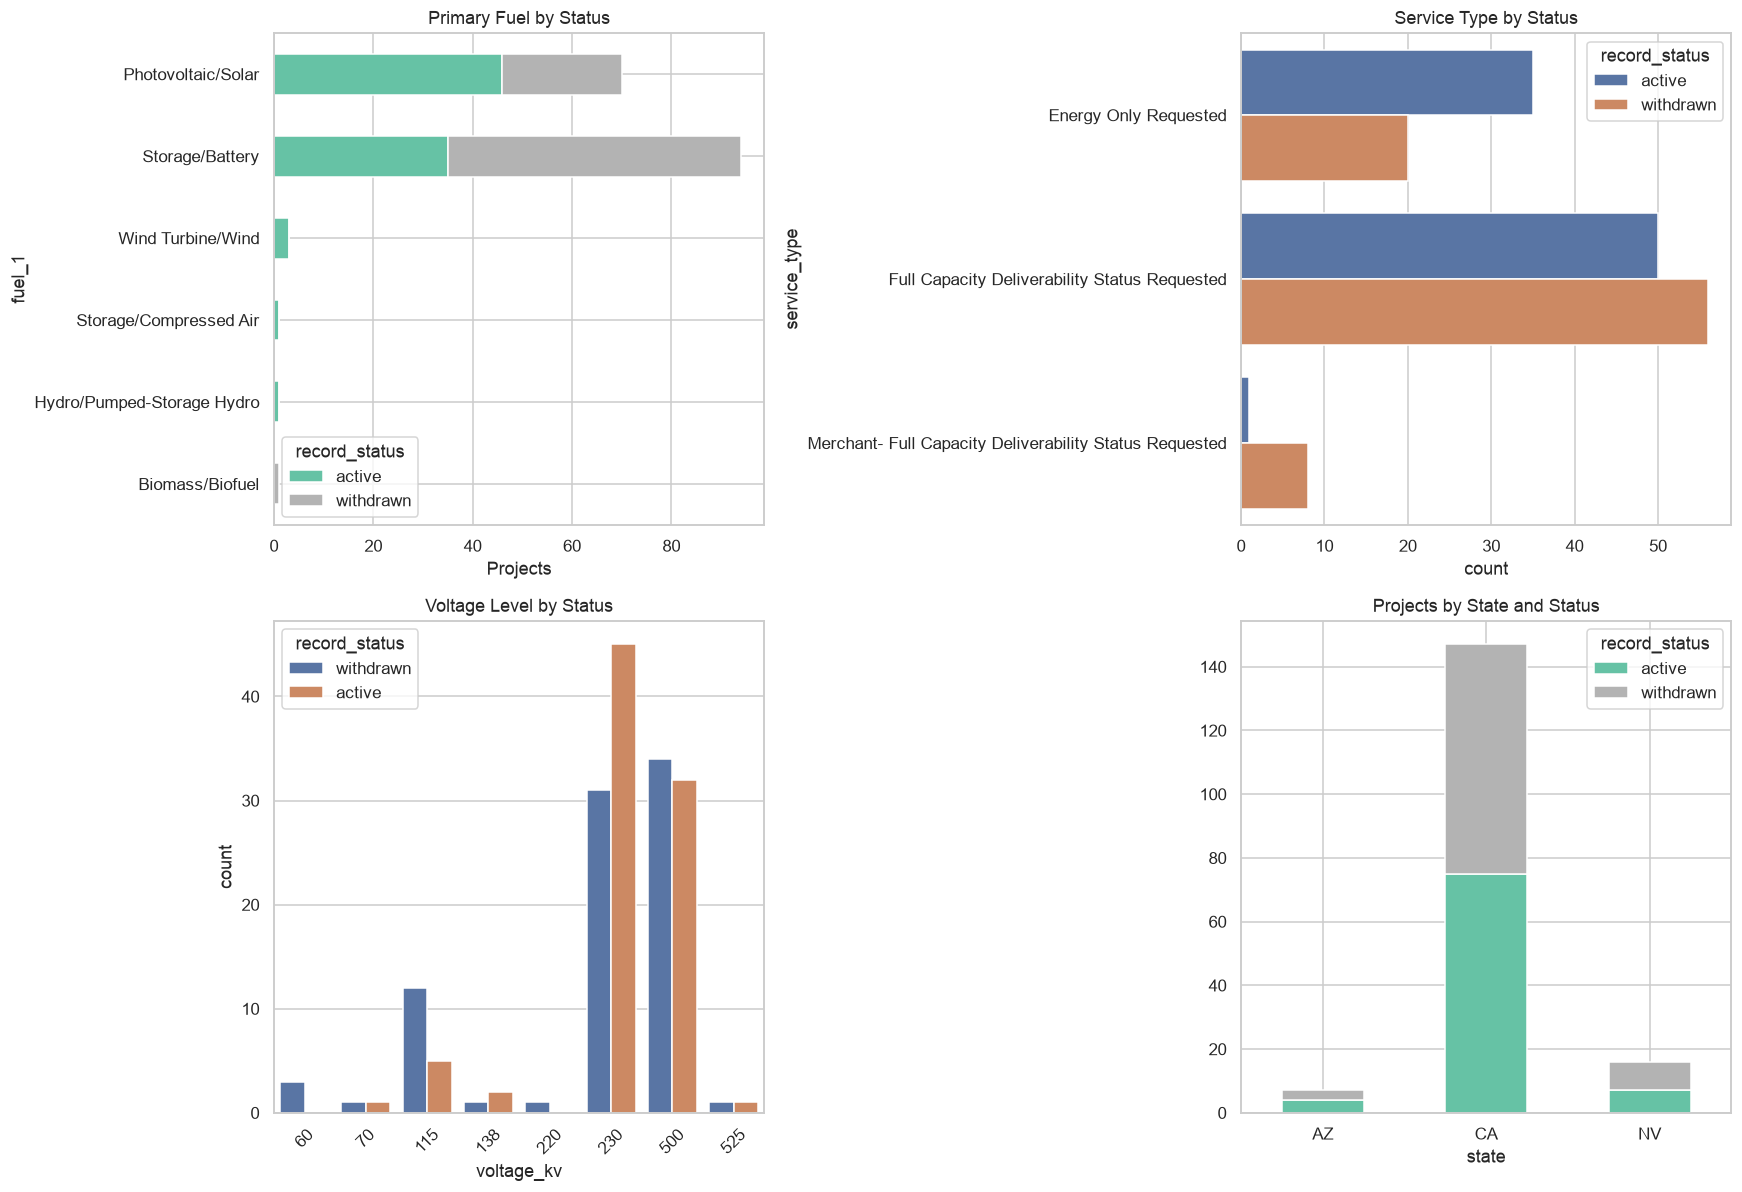

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

fuel_counts = pd.crosstab(all_projects["fuel_1"], all_projects["record_status"])
fuel_counts.sort_values("active").plot.barh(stacked=True, ax=axes[0, 0], colormap="Set2")
axes[0, 0].set_title("Primary Fuel by Status")
axes[0, 0].set_xlabel("Projects")

sns.countplot(data=all_projects, y="service_type", hue="record_status", ax=axes[0, 1])
axes[0, 1].set_title("Service Type by Status")

sns.countplot(data=all_projects, x="voltage_kv", hue="record_status", ax=axes[1, 0])
axes[1, 0].set_title("Voltage Level by Status")
axes[1, 0].tick_params(axis="x", rotation=45)

state_counts = pd.crosstab(all_projects["state"], all_projects["record_status"])
state_counts.plot.bar(stacked=True, ax=axes[1, 1], colormap="Set2")
axes[1, 1].set_title("Projects by State and Status")
axes[1, 1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 8. California solar cohort

,projects,poi_mw,median_mw,hybrid_share
record_status,,,,
active,36,12725.75,300.0,0.694444
withdrawn,16,5729.00,225.0,0.687500


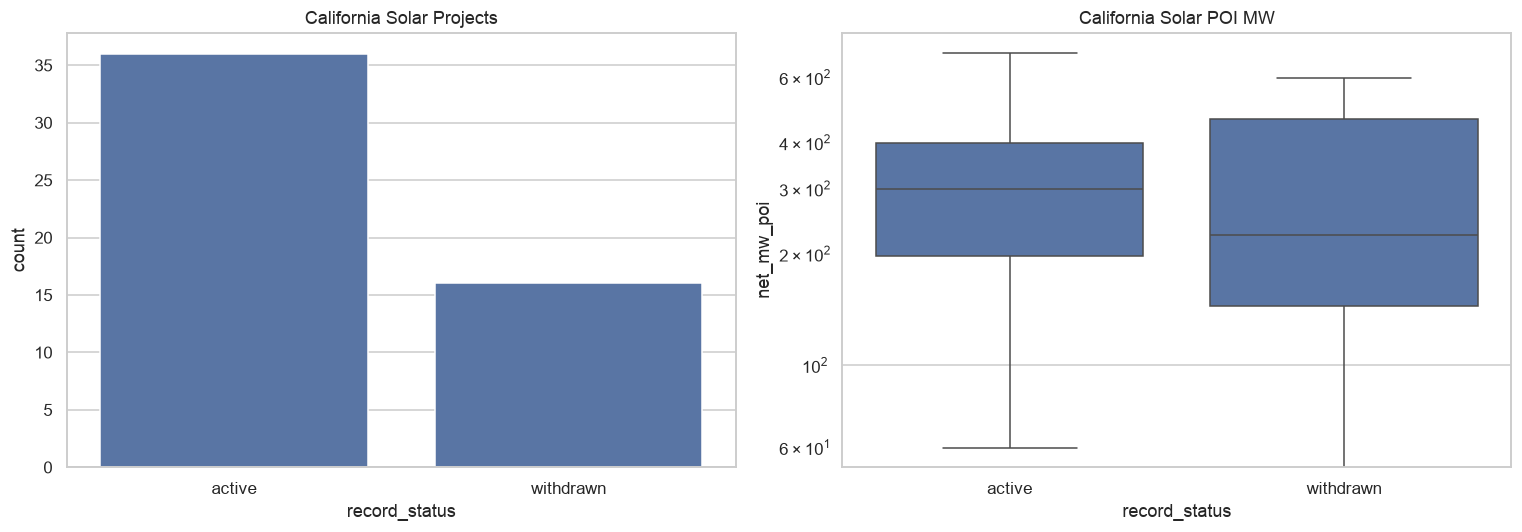

In [9]:
ca_solar = all_projects[
    all_projects["state"].eq("CA")
    & all_projects["fuel_1"].astype(str).str.contains("Solar", case=False, na=False)
].copy()

ca_solar_summary = (
    ca_solar.groupby("record_status")
            .agg(
                projects=("queue_id", "size"),
                poi_mw=("net_mw_poi", "sum"),
                median_mw=("net_mw_poi", "median"),
                hybrid_share=("is_hybrid", "mean"),
            )
)
display(ca_solar_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=ca_solar, x="record_status", ax=axes[0])
axes[0].set_title("California Solar Projects")
sns.boxplot(data=ca_solar, x="record_status", y="net_mw_poi",
            showfliers=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("California Solar POI MW")
plt.tight_layout()
plt.show()

## 9. Application, COD, and withdrawal timing

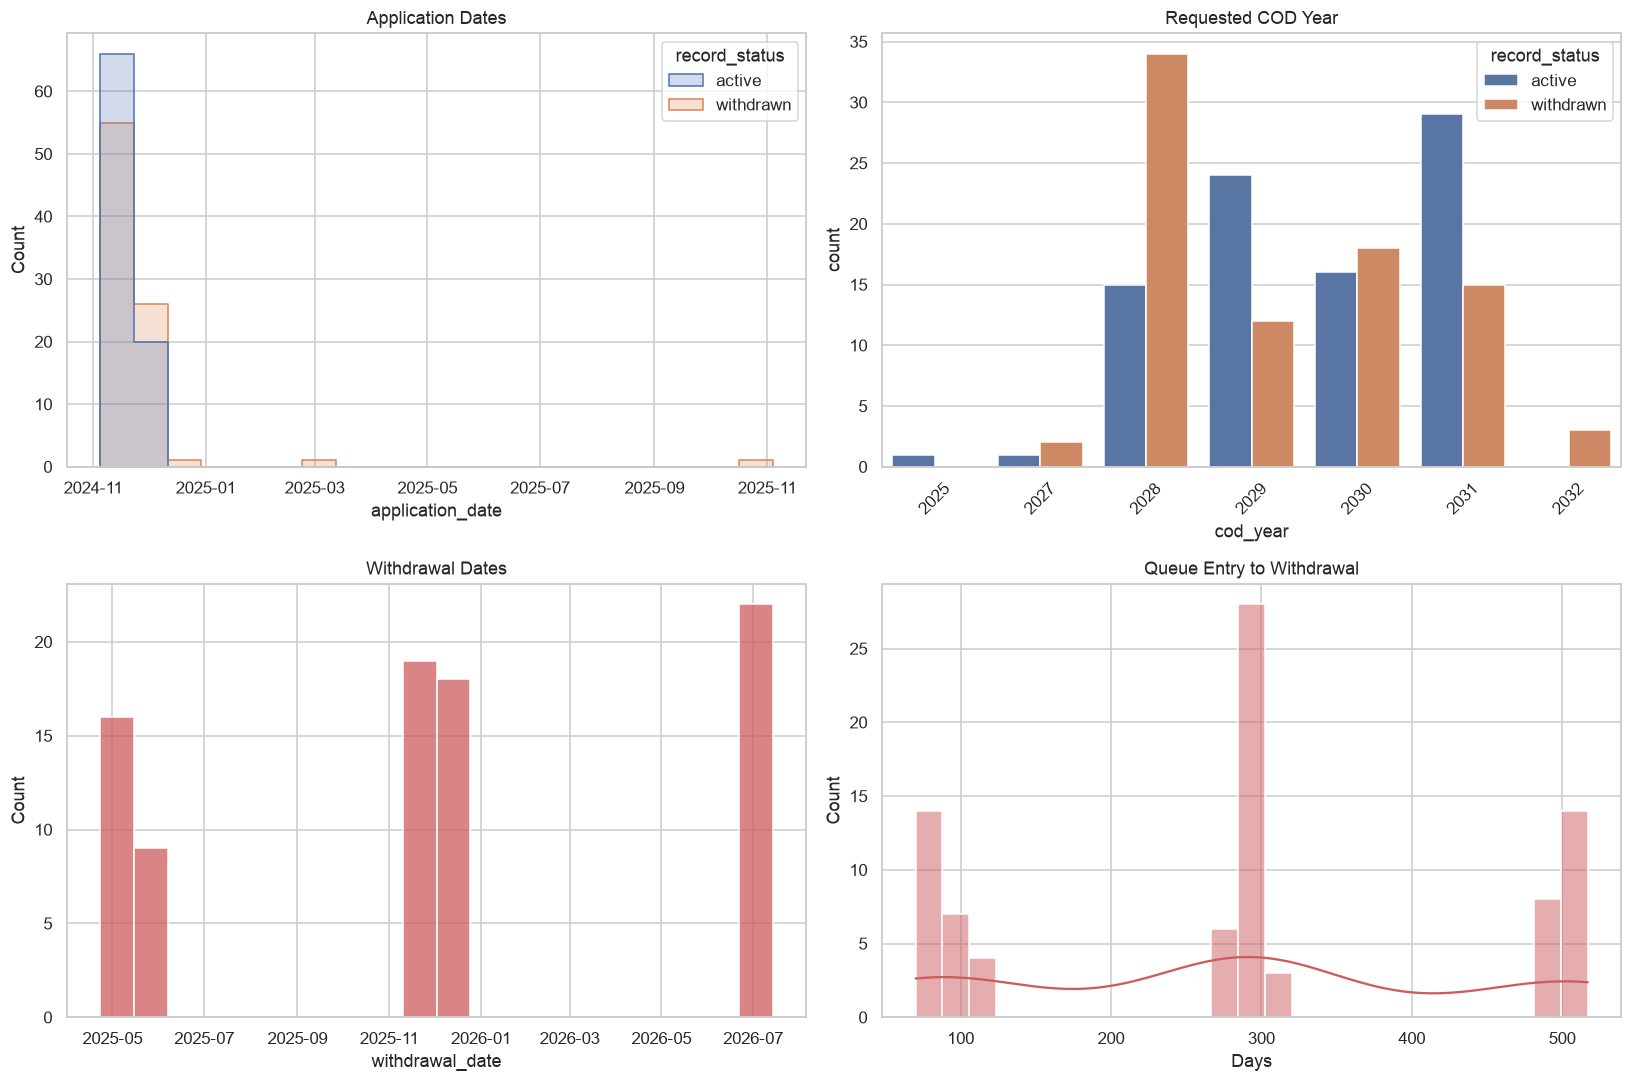

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(data=all_projects, x="application_date", hue="record_status",
             bins=20, element="step", ax=axes[0, 0])
axes[0, 0].set_title("Application Dates")

sns.countplot(data=all_projects, x="cod_year", hue="record_status", ax=axes[0, 1])
axes[0, 1].set_title("Requested COD Year")
axes[0, 1].tick_params(axis="x", rotation=45)

sns.histplot(withdrawn["withdrawal_date"].dropna(), bins=20,
             color="indianred", ax=axes[1, 0])
axes[1, 0].set_title("Withdrawal Dates")

withdrawal_days = all_projects.loc[
    (all_projects["record_status"] == "withdrawn")
    & (all_projects["days_queue_to_withdrawal"] >= 0),
    "days_queue_to_withdrawal",
]
sns.histplot(withdrawal_days, bins=25, kde=True, color="indianred", ax=axes[1, 1])
axes[1, 1].set_title("Queue Entry to Withdrawal")
axes[1, 1].set_xlabel("Days")
plt.tight_layout()
plt.show()

## 10. Cross-dataset overlap and leakage controls

In [11]:
# Berkeley uses q_id as the CAISO queue identifier. Load correctly with row 1 as header.
berkeley = pd.read_excel(
    BERKELEY_PATH, sheet_name="03. Complete Queue Data", header=1
)
berkeley.columns = berkeley.columns.astype(str).str.strip()
berkeley_ids = set(pd.to_numeric(berkeley["q_id"], errors="coerce").dropna().astype(int))
c15_ids = set(pd.to_numeric(all_projects["queue_id"], errors="coerce").dropna().astype(int))

# The older CAISO workbook uses Queue Position.
c14_active = pd.read_excel(C14_PATH, sheet_name="Grid GenerationQueue", skiprows=3)
c14_ids = set(pd.to_numeric(c14_active["Queue Position"], errors="coerce").dropna().astype(int))

overlap = pd.DataFrame({
    "comparison": ["Cluster 15 vs Berkeley", "Cluster 15 vs older CAISO active"],
    "cluster15_ids": [len(c15_ids), len(c15_ids)],
    "overlap_ids": [len(c15_ids & berkeley_ids), len(c15_ids & c14_ids)],
})
display(overlap)

berkeley_c15 = berkeley[
    pd.to_numeric(berkeley["q_id"], errors="coerce").isin(c15_ids)
][["q_id", "q_status", "region", "state", "cluster"]].copy()
reconciliation = pd.crosstab(
    all_projects.set_index("queue_id")["record_status"],
    berkeley_c15.assign(q_id=pd.to_numeric(berkeley_c15["q_id"], errors="coerce"))
                 .set_index("q_id")["q_status"],
)
display(reconciliation)
print("All overlapping Cluster 15 IDs must be excluded from Berkeley model development before scoring this workbook.")

,comparison,cluster15_ids,overlap_ids
0,Cluster 15 vs Berkeley,170,170
1,Cluster 15 vs older CAISO active,170,0


q_status,active,withdrawn
record_status,,
active,86,0
withdrawn,22,62


All overlapping Cluster 15 IDs must be excluded from Berkeley model development before scoring this workbook.


## 11. Feature policy for future scoring

In [12]:
feature_policy = pd.DataFrame([
    ("net_mw_poi, voltage_kv", "Use", "Queue-entry project scale and connection voltage"),
    ("fuel_1/2/3, is_hybrid", "Use", "Technology configuration"),
    ("service_type, state, county, study_area, PTO", "Use/encode carefully", "Application context"),
    ("requested_cod and derived horizon", "Use", "Known requested schedule"),
    ("queue_id, project_id, project_name", "Exclude", "Identifiers"),
    ("POI name", "Conditional", "High cardinality; may be better suited to SQL/RAG"),
    ("withdrawal_date", "Exclude", "Direct post-outcome leakage"),
    ("record_status, source_sheet", "Target/metadata only", "Directly encode current status"),
], columns=["feature_group", "policy", "reason"])
display(feature_policy)

,feature_group,policy,reason
0,"net_mw_poi, voltage_kv",Use,Queue-entry project scale and connection voltage
1,"fuel_1/2/3, is_hybrid",Use,Technology configuration
2,"service_type, state, county, study_area, PTO",Use/encode carefully,Application context
3,requested_cod and derived horizon,Use,Known requested schedule
4,"queue_id, project_id, project_name",Exclude,Identifiers
5,POI name,Conditional,High cardinality; may be better suited to SQL/RAG
6,withdrawal_date,Exclude,Direct post-outcome leakage
7,"record_status, source_sheet",Target/metadata only,Directly encode current status


## 12. What this workbook can and cannot tell us

### It can support
- Description of active and withdrawn Cluster 15 projects.
- Current California solar-project inference after a model is trained elsewhere.
- Withdrawal timing and technology/capacity comparisons.
- Domain-shift and feature-alignment checks against historical data.

### It cannot support by itself
- An operational-versus-withdrawn classifier because there are no completed/operational rows.
- Accuracy validation on its active projects because their final outcomes are unknown.
- Causal explanations for withdrawal because cost, detailed study findings, financing, permitting, and grid constraints are absent.

Active-versus-withdrawn comparisons are descriptive snapshot comparisons, not clean terminal-outcome labels.

## 13. Final assessment

1. Use Berkeley Lab’s resolved CAISO/California records as the canonical labeled source for the initial classifier.
2. Define the target as **eventually operational/completed before withdrawal**.
3. Remove every overlapping Cluster 15 queue ID from Berkeley training and validation before scoring these projects.
4. Use the 86 active records as the production inference cohort and the 84 withdrawn records for recent-cohort/descriptive checks.
5. Evaluate with temporal holdouts, PR-AUC, recall/precision, Brier score, and calibration because withdrawals dominate.
6. Optionally build a competing-risks survival model to estimate time to operation or withdrawal, treating active projects as right-censored.

The agent should say “probability of reaching operation before withdrawal,” not “formal approval probability.”